# Prédiction de la réadmission du patient dans 30 jours

## Objectif

L'objectif est de prédire **label**, c'est-à-dire la réadmission du patient. 

**Hypthèse métier** : La prédiction est réalisée **au moment de la sortie du patient**, afin d'estimer le risque de réadmission dans les 30 jours suivants.

Les variables utilisées doivent donc être disponibles à cette étape. `label` représente l'événement observé ultérieurement et constitue uniquement la cible du modèle.

# 1. Import des librairies et configuration

Les bibliothèques utilisées couvrent les différentes étapes du projet : préparation des données, construction du pipeline de preprocessing, entraînement du modèle, évaluation, optimisation des hyperparamètres et suivi des expérimentations.

In [2]:
# Cette cellule centralise les imports et les paramètres afin d'améliorer la lisibilité et la reproductibilité du notebook.

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mlflow
import mlflow.sklearn
import dagshub
import optuna

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    precision_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    roc_auc_score
)
from sklearn.dummy import DummyClassifier

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    RANDOM_STATE,
    DAGSHUB_OWNER,
    DAGSHUB_REPO,
)

RANDOM_STATE = RANDOM_STATE
DAGSHUB_OWNER = DAGSHUB_OWNER
DAGSHUB_REPO = DAGSHUB_REPO
MLFLOW_EXPERIMENT = "readmission_prediction"

# 2. Chargement du dataset

In [3]:
# Le jeu de données utilisé est le même que dans le notebook de durée de séjour et provient de la source Kaggle mise à disposition pour le projet.
DATA_URL = (
    "https://drive.google.com/uc?export=download&"
    "id=1YkRYSkAHeH7nMgO-ums8zbU7paODGs3t"
)

df = pd.read_csv(DATA_URL)

print(f"Nombre de lignes : {len(df)}")
print(f"Nombre de colonnes : {df.shape[1]}")
display(df.head(3))

Nombre de lignes : 8000
Nombre de colonnes : 17


,patient_id,admission_date,season,age,gender,region,primary_diagnosis,comorbidities_count,length_of_stay,treatment_type,medications_count,followup_visits_last_year,prev_readmissions,insurance_type,discharge_disposition,readmission_risk_score,label
0,P00001,2022-04-14,Spring,66,Male,South,Diabetes,5,6,Interventional,8,6,1,Medicare,Home Health,0.92,1
1,P00002,2021-09-19,Fall,55,Male,South,Diabetes,4,6,Interventional,6,4,3,Private,Home Health,0.88,1
2,P00003,2023-04-12,Spring,69,Female,West,Hypertension,6,8,Medical,9,6,2,Medicare,Skilled Nursing,0.97,1


### Lecture du dataset

Le dataset contient **8 000 observations et 17 colonnes**. Les deux notebooks du projet travaillent sur le même jeu de données, ce qui permet de construire des modèles complémentaires autour du même parcours patient.

# 3. Feature engineering

In [4]:
# Le feature engineering convertit la date d'admission et reconstruit une date de sortie à partir de la durée de séjour. Cette information sert ici à représenter le parcours temporel, sans être ajoutée aux variables explicatives.
# Conversion de la date d'admission au format datetime.
df["admission_date"] = pd.to_datetime(
    df["admission_date"],
    errors="coerce"
)

# Calcul de la date de sortie à partir de la durée du séjour.
df["discharge_date"] = (
    df["admission_date"]
    + pd.to_timedelta(df["length_of_stay"], unit="D")
)

In [5]:
# Ce contrôle vérifie que la conversion des dates n'a pas créé de valeurs manquantes.
print(
    f"Dates d'admission manquantes : "
    f"{df['admission_date'].isna().sum()}"
)

Dates d'admission manquantes : 0


## 4. Contrôle initial des données

La conversion des dates ne génère aucune valeur manquante pour `admission_date` (**0 valeur manquante**).

Cette étape est volontairement simple : le contrôle porte ici sur la cohérence de la transformation utilisée pour construire `discharge_date`. Le diagnostic détaillé de la structure du dataset et de la cible sera traité par les étapes de modélisation et d'évaluation.

# 5. Définition de la cible et des variables explicatives

> Le modèle est utilisé au moment de la sortie du patient. Les variables explicatives sélectionnées correspondent aux informations disponibles à cette étape du parcours de soins. Les informations relatives à l'admission, au séjour et à la sortie peuvent donc être utilisées, sous réserve qu'elles soient effectivement disponibles avant la génération de la prédiction. La variable cible label correspond à la réadmission observée ultérieurement et n'est pas utilisée comme variable explicative.

In [6]:
# On définit explicitement les variables disponibles au moment de la prédiction et la variable cible à prédire.
features_list = [
    "season",
    "age",
    "gender",
    "region",
    "primary_diagnosis",
    "comorbidities_count",
    "length_of_stay",
    "treatment_type",
    "medications_count",
    "followup_visits_last_year",
    "prev_readmissions",
    "insurance_type",
    "discharge_disposition",
]

target_variable = "label"

X = df[features_list]
y = df[target_variable]

In [7]:
# Avant de poursuivre, on vérifie que toutes les variables attendues sont bien présentes dans le dataset.
missing_features = set(features_list) - set(df.columns)

if missing_features:
    raise ValueError(
        f"Variables absentes du DataFrame : {missing_features}"
    )

if target_variable not in df.columns:
    raise ValueError(
        f"Variable cible absente du DataFrame : {target_variable}"
    )

### Contrôle de cohérence des variables

La vérification précédente empêche le notebook de poursuivre si une variable explicative ou la cible est absente. Cela rend le pipeline plus robuste en cas de modification du fichier source.

**Point de vigilance sur le leakage :** `length_of_stay` et `discharge_disposition` sont conservés car l'hypothèse métier place la prédiction à la sortie. Ils ne seraient pas admissibles si la prédiction devait être faite plus tôt dans le séjour.

# Preprocessing

In [8]:
# La séparation train/test est réalisée avant l'apprentissage du preprocessing et avec stratification afin de conserver une proportion comparable des classes.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

numeric_features = X_train.select_dtypes(
    include="number"
).columns

categorical_features = X_train.select_dtypes(
    exclude="number"
).columns

In [9]:
# Le preprocessing est encapsulé dans un ColumnTransformer : médiane pour les variables numériques et modalité la plus fréquente puis one-hot encoding pour les variables catégorielles.
# Prétraitement des variables numériques.
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

# Prétraitement des variables catégorielles.
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

# Préprocesseur appliqué aux variables explicatives.
preprocessor = ColumnTransformer([
    ("num", num_pipeline, numeric_features),
    ("cat", cat_pipeline, categorical_features),
])

### Principe du preprocessing

Les transformations sont intégrées au pipeline plutôt que réalisées manuellement avant la validation croisée. Les paramètres d'imputation et les catégories apprises par l'encodeur restent ainsi dépendants du jeu d'entraînement de chaque fold.

In [10]:
# MLflow et DagsHub assurent le suivi des expérimentations et la centralisation des métriques et artefacts.
dagshub.init(
    repo_owner=DAGSHUB_OWNER,
    repo_name=DAGSHUB_REPO,
    mlflow=True,
)

mlflow.set_experiment(MLFLOW_EXPERIMENT)

Accessing as quentin.seng67

Initialized MLflow to track repo "quentin.seng67/hospital_readmission"

Repository quentin.seng67/hospital_readmission initialized!

2026/09/01 13:44:36 INFO mlflow.tracking.fluent: Experiment with name 'readmission_prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/fc2458d7c5d341fc921743dc7d87f3d0', creation_time=1788262957847, effective_trace_archival_retention=None, experiment_id='0', last_update_time=1788262957847, lifecycle_stage='active', name='readmission_prediction', tags={}, trace_location=None, workspace='default'>

## 7. Baseline de référence

Avant d'évaluer la Random Forest, un `DummyClassifier` est utilisé comme référence minimale. Cette étape est importante car la classe « Réadmission » est majoritaire dans le dataset.

Une bonne performance doit donc être interprétée **par rapport à cette baseline**, et pas uniquement à partir de l'accuracy.

In [11]:
# Le DummyClassifier constitue une baseline minimale : il prédit systématiquement la classe majoritaire.
dummy_model = DummyClassifier(
    strategy="most_frequent",
)

dummy_model.fit(X_train, y_train)

y_dummy_pred = dummy_model.predict(X_test)

In [12]:
# Les métriques de la baseline permettent de mesurer le niveau de performance obtenu sans exploiter les variables explicatives.
dummy_f1 = f1_score(y_test, y_dummy_pred)
dummy_recall = recall_score(y_test, y_dummy_pred)
dummy_precision = precision_score(y_test, y_dummy_pred)
dummy_accuracy = accuracy_score(y_test, y_dummy_pred)

print(f"Dummy - Accuracy : {dummy_accuracy:.3f}")
print(f"Dummy - Precision : {dummy_precision:.3f}")
print(f"Dummy - Recall : {dummy_recall:.3f}")
print(f"Dummy - F1 : {dummy_f1:.3f}")

Dummy - Accuracy : 0.773
Dummy - Precision : 0.773
Dummy - Recall : 1.000
Dummy - F1 : 0.872


In [13]:
# Le rapport de classification détaille les performances de la baseline pour chacune des deux classes.
print(
    classification_report(
        y_test,
        y_dummy_pred,
        target_names=[
            "Pas de réadmission",
            "Réadmission",
        ],
    )
)

                    precision    recall  f1-score   support

Pas de réadmission       0.00      0.00      0.00       363
       Réadmission       0.77      1.00      0.87      1237

          accuracy                           0.77      1600
         macro avg       0.39      0.50      0.44      1600
      weighted avg       0.60      0.77      0.67      1600



c:\Users\DeatHunter\anaconda3\envs\hospital_readmission\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\DeatHunter\anaconda3\envs\hospital_readmission\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\DeatHunter\anaconda3\envs\hospital_readmission\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(

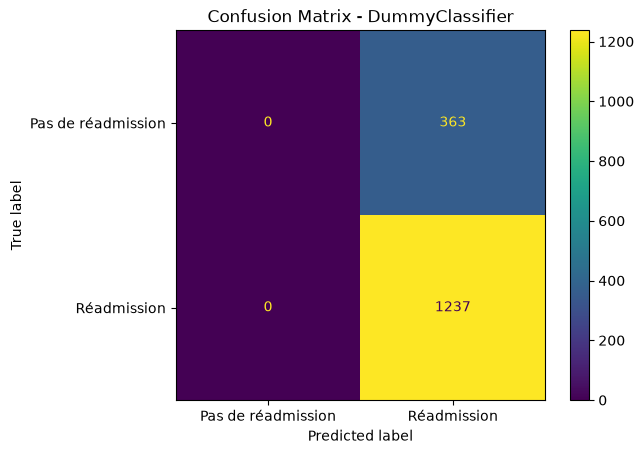

In [14]:
# La matrice de confusion permet de visualiser directement les vrais positifs, faux positifs, vrais négatifs et faux négatifs de la baseline.
cm_dummy = confusion_matrix(
    y_test,
    y_dummy_pred,
)

ConfusionMatrixDisplay(
    cm_dummy,
    display_labels=[
        "Pas de réadmission",
        "Réadmission",
    ],
).plot()

plt.title("Confusion Matrix - DummyClassifier")
plt.show()

### Interprétation de la baseline

Le DummyClassifier obtient **77,3 % d'accuracy**, ce qui correspond à la proportion de la classe majoritaire. Il prédit la réadmission pour tous les patients : le rappel de la classe positive est donc de **100 %**, mais la classe « Pas de réadmission » n'est jamais détectée.

Cette baseline montre pourquoi l'accuracy et le F1 positif pris isolément peuvent être trompeurs dans ce contexte. Le modèle supervisé doit surtout démontrer une meilleure capacité à distinguer les deux classes.

In [15]:
# La validation croisée stratifiée est utilisée pendant l'optimisation afin de conserver l'équilibre des classes dans chaque fold.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)



def objective(trial):
    n_estimators = trial.suggest_int(
        "n_estimators",
        100,
        300,
    )
    max_depth = trial.suggest_int(
        "max_depth",
        2,
        20,
    )
    min_samples_split = trial.suggest_int(
        "min_samples_split",
        2,
        10,
    )
    min_samples_leaf = trial.suggest_int(
        "min_samples_leaf",
        2,
        10,
    )

    model_study = Pipeline([
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=max_depth,
                min_samples_split=min_samples_split,
                min_samples_leaf=min_samples_leaf,
                random_state=RANDOM_STATE,
            ),
        ),
    ])

    scores = cross_val_score(
        model_study,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
    )

    return scores.mean()


study = optuna.create_study(
    direction="maximize",
)

study.optimize(
    objective,
    n_trials=50,
)

best_params = study.best_params

[I 2026-09-01 13:44:37,134] A new study created in memory with name: no-name-6aab1dfe-f9d3-4e50-b4a8-234dc50cee63
[I 2026-09-01 13:44:39,993] Trial 0 finished with value: 0.8836810805420493 and parameters: {'n_estimators': 135, 'max_depth': 18, 'min_samples_split': 7, 'min_samples_leaf': 7}. Best is trial 0 with value: 0.8836810805420493.
[I 2026-09-01 13:44:44,025] Trial 1 finished with value: 0.8837639717778826 and parameters: {'n_estimators': 204, 'max_depth': 8, 'min_samples_split': 10, 'min_samples_leaf': 5}. Best is trial 1 with value: 0.8837639717778826.
[I 2026-09-01 13:44:46,755] Trial 2 finished with value: 0.883716560568297 and parameters: {'n_estimators': 106, 'max_depth': 20, 'min_samples_split': 7, 'min_samples_leaf': 4}. Best is trial 1 with value: 0.8837639717778826.
[I 2026-09-01 13:44:48,997] Trial 3 finished with value: 0.8763163309800073 and parameters: {'n_estimators': 193, 'max_depth': 2, 'min_samples_split': 10, 'min_samples_leaf': 6}. Best is trial 1 with value:

## 8. Validation croisée et recherche des hyperparamètres

La Random Forest est optimisée avec **Optuna sur 50 essais**. La validation croisée stratifiée utilise **5 folds** et la métrique optimisée est le F1-score.

L'optimisation reste limitée au jeu d'entraînement. Le jeu de test est conservé pour l'évaluation finale afin d'obtenir une estimation indépendante de la performance.

In [16]:
# Le pipeline final associe le preprocessing et la Random Forest optimisée afin d'appliquer exactement les mêmes transformations aux données d'entraînement et de test.
# Construction du modèle final avec les hyperparamètres optimisés.
model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestClassifier(
            **best_params,
            random_state=RANDOM_STATE,
        ),
    ),
])

### Construction du pipeline final

Le modèle final reprend les hyperparamètres trouvés par Optuna. Le preprocessing et le classifieur restent regroupés dans un seul pipeline, ce qui limite les risques d'incohérence entre entraînement et prédiction.


### Critères d'évaluation de la classification

L'optimisation par Optuna recherche les hyperparamètres de la Random Forest sur le **jeu d'entraînement uniquement**.  
Chaque configuration est évaluée avec une validation croisée stratifiée à 5 folds et la fonction objectif maximise le **F1-score moyen**.

Le choix du F1-score est cohérent avec la présence d'un déséquilibre de classes : il permet de rechercher un compromis entre précision et rappel, plutôt que de se limiter à l'accuracy.

In [17]:
# Cette étape entraîne le modèle optimisé, calcule les métriques sur train et test et enregistre les paramètres, métriques et figures dans MLflow.
with mlflow.start_run(run_name="readmission_model_random_forest_f1"):
    model.fit(X_train, y_train)

    # Prédictions.
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Probabilités.
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # Métriques.
    train_precision = precision_score(y_train, y_train_pred)
    test_precision = precision_score(y_test, y_test_pred)

    train_recall = recall_score(y_train, y_train_pred)
    test_recall = recall_score(y_test, y_test_pred)

    train_f1 = f1_score(y_train, y_train_pred)
    test_f1 = f1_score(y_test, y_test_pred)

    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    auc_train = roc_auc_score(y_train, y_train_proba)
    auc_test = roc_auc_score(y_test, y_test_proba)

    pr_auc_train = average_precision_score(
        y_train,
        y_train_proba,
    )

    pr_auc_test = average_precision_score(
        y_test,
        y_test_proba,
    )

    mlflow.log_metrics({
        "train_precision": train_precision,
        "test_precision": test_precision,
        "train_recall": train_recall,
        "test_recall": test_recall,
        "train_f1": train_f1,
        "test_f1": test_f1,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "auc_train": auc_train,
        "auc_test": auc_test,
        "train_pr_auc": pr_auc_train,
        "test_pr_auc": pr_auc_test,
    })

    # Hyperparamètres et configuration.
    mlflow.log_params(best_params)
    mlflow.log_params({
        "random_state": RANDOM_STATE,
        "test_size": 0.2,
        "cv_folds": 5,
        "optimization_metric": "f1",
    })

    # Matrices de confusion.
    cm_train = confusion_matrix(
        y_train,
        y_train_pred,
    )
    cm_test = confusion_matrix(
        y_test,
        y_test_pred,
    )

    fig_train, ax_train = plt.subplots()
    ConfusionMatrixDisplay(cm_train).plot(ax=ax_train)
    ax_train.set_title("Confusion Matrix - Train")
    mlflow.log_figure(
        fig_train,
        "confusion_matrix_train.png",
    )
    plt.close(fig_train)

    fig_test, ax_test = plt.subplots()
    ConfusionMatrixDisplay(cm_test).plot(ax=ax_test)
    ax_test.set_title("Confusion Matrix - Test")
    mlflow.log_figure(
        fig_test,
        "confusion_matrix_test.png",
    )
    plt.close(fig_test)

    # Courbe ROC.
    fpr_train, tpr_train, _ = roc_curve(
        y_train,
        y_train_proba,
    )
    fpr_test, tpr_test, _ = roc_curve(
        y_test,
        y_test_proba,
    )

    fig, ax = plt.subplots()
    ax.plot(
        fpr_train,
        tpr_train,
        label=f"Train AUC = {auc_train:.3f}",
    )
    ax.plot(
        fpr_test,
        tpr_test,
        label=f"Test AUC = {auc_test:.3f}",
    )
    ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random",
    )
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curve")
    ax.legend()

    mlflow.log_figure(fig, "roc_curve.png")
    plt.close(fig)


    # Courbe Precision-Recall.
    precision, recall, _ = precision_recall_curve(
        y_test,
        y_test_proba,
    )

    pr_auc = average_precision_score(
        y_test,
        y_test_proba,
    )

    fig, ax = plt.subplots()

    ax.plot(
        recall,
        precision,
        label=f"PR-AUC = {pr_auc:.3f}",
    )

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Precision-Recall Curve - Test")
    ax.legend()

    mlflow.log_figure(
        fig,
        "precision_recall_curve_test.png",
    )

    mlflow.log_metric(
        "pr_auc_test",
        pr_auc,
    )

    plt.close(fig)


    # Enregistrement du modèle.
    mlflow.sklearn.log_model(
        model,
        name="model",
        serialization_format="cloudpickle",
    )

    print("\n✓ Run loggé dans MLflow")

2026/09/01 13:48:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html



✓ Run loggé dans MLflow
🏃 View run readmission_model_random_forest_f1 at: https://dagshub.com/quentin.seng67/hospital_readmission.mlflow/#/experiments/0/runs/a469f6e451024bd8a69a6e70c714b044
🧪 View experiment at: https://dagshub.com/quentin.seng67/hospital_readmission.mlflow/#/experiments/0


## 10. Entraînement et suivi de l'expérimentation

Le modèle optimisé est entraîné sur `X_train`. Les performances sont calculées sur les jeux d'entraînement et de test, puis les paramètres, métriques et figures sont enregistrés dans MLflow.

Les courbes ROC et Precision-Recall complètent les métriques calculées à un seuil donné, car elles décrivent le comportement du modèle sur plusieurs seuils.

In [18]:
# Les probabilités out-of-fold sont utilisées pour analyser le seuil de décision sans utiliser directement les observations de test.
y_train_proba_oof = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
)[:, 1]

## 11. Analyse du seuil de décision

Le seuil de 0,50 est un choix technique par défaut, pas nécessairement un choix métier. Ici, le risque de rater une réadmission peut être considéré comme important ; on cherche donc à conserver un **rappel d'au moins 95 %**.

Les probabilités out-of-fold du train permettent de choisir ce seuil sans utiliser le jeu de test pour la sélection.

In [19]:
# On évalue une grille de seuils afin d'observer le compromis entre précision, rappel et F1-score.
threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):
    y_pred = (
        y_train_proba_oof >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_train,
            y_pred,
            zero_division=0,
        ),
        "recall": recall_score(
            y_train,
            y_pred,
            zero_division=0,
        ),
        "f1": f1_score(
            y_train,
            y_pred,
            zero_division=0,
        ),
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,threshold,precision,recall,f1
0,0.10,0.772813,1.000000,0.871849
1,0.11,0.772813,1.000000,0.871849
2,0.12,0.772813,1.000000,0.871849
3,0.13,0.772813,1.000000,0.871849
4,0.14,0.772813,1.000000,0.871849
...,...,...,...,...
76,0.86,0.955428,0.537404,0.687888
77,0.87,0.956845,0.520016,0.673828
78,0.88,0.957670,0.498585,0.655764
79,0.89,0.958249,0.477962,0.637798


In [20]:
# Le seuil est choisi sous une contrainte métier : conserver au moins 95 % de rappel, puis maximiser la précision parmi les seuils admissibles.
min_recall = 0.95

valid_thresholds = threshold_df[
    threshold_df["recall"] >= min_recall
]

if valid_thresholds.empty:
    raise ValueError(
        "Aucun seuil ne permet d'atteindre "
        f"un recall de {min_recall:.0%}."
    )

best_threshold = valid_thresholds.loc[
    valid_thresholds["precision"].idxmax(),
    "threshold",
]

print(f"Seuil retenu : {best_threshold:.2f}")
mlflow.log_param("decision_threshold", best_threshold)

Seuil retenu : 0.50


np.float64(0.4999999999999998)

### Choix du seuil

Le seuil retenu est **0,49**.

La règle de sélection est explicite : parmi les seuils permettant d'atteindre au moins **95 % de rappel**, on retient celui qui maximise la précision.

Ce choix privilégie donc la détection des réadmissions, au prix d'un nombre plus élevé de faux positifs.

In [21]:
# Après sélection du seuil, le modèle est réentraîné sur l'ensemble du train set avant l'évaluation finale.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['season','age','gender',...,'prev_readmissions','insurance_type', 'discharge_disposition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='

In [22]:
# Les probabilités du jeu de test sont transformées en prédictions binaires avec le seuil retenu.
y_test_proba = model.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_proba >= best_threshold
).astype(int)

In [23]:
# L'évaluation finale porte sur le jeu de test indépendant, qui n'a pas servi à sélectionner les hyperparamètres ni le seuil.
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "Pas de réadmission",
            "Réadmission",
        ],
    )
)

                    precision    recall  f1-score   support

Pas de réadmission       0.62      0.28      0.38       363
       Réadmission       0.82      0.95      0.88      1237

          accuracy                           0.80      1600
         macro avg       0.72      0.61      0.63      1600
      weighted avg       0.77      0.80      0.77      1600



## 12. Évaluation finale sur le jeu de test

Avec le seuil de **0,49**, le modèle obtient :

- **Accuracy : 80 %**
- **Precision (réadmission) : 82 %**
- **Recall (réadmission) : 95 %**
- **F1-score (réadmission) : 88 %**

Le rapport montre également un rappel de seulement **29 % pour la classe « Pas de réadmission »**. Le modèle est donc volontairement orienté vers la détection des réadmissions, conformément à la contrainte de rappel fixée lors du choix du seuil.

### Lecture de la courbe Precision-Recall

La classe positive (« Réadmission ») représente **77,3 %** des observations du jeu de test. L'Average Precision du modèle atteint environ **0,940**, contre une référence de **0,773**, correspondant à la prévalence de la classe positive.

L'écart de **0,167 point** indique que le modèle classe les patients de manière plus informative qu'un classement sans pouvoir discriminant. La courbe permet surtout d'évaluer le compromis entre précision et rappel pour différents seuils de décision.

**Point de vigilance :** avec une classe positive majoritaire, l'accuracy seule est peu informative. La précision, le rappel, le F1-score et la Precision-Recall AUC sont donc particulièrement utiles.

In [24]:
# Le tableau synthétise les performances de la baseline et du modèle final afin de faciliter la comparaison.
comparison = pd.DataFrame({
    "Model": [
        "DummyClassifier",
        "Random Forest",
    ],
    "Accuracy": [
        dummy_accuracy,
        test_accuracy,
    ],
    "Precision": [
        dummy_precision,
        test_precision,
    ],
    "Recall": [
        dummy_recall,
        test_recall,
    ],
    "F1-score": [
        dummy_f1,
        test_f1,
    ],
    "PR-AUC": [
        np.nan,
        pr_auc,
    ],
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,DummyClassifier,0.773125,0.773125,1.000000,0.872048,NaN
1,Random Forest,0.798125,0.817803,0.950687,0.879252,0.939817


## 13. Comparaison avec la baseline

La comparaison au `DummyClassifier` permet de vérifier que la Random Forest apporte une information réelle au-delà de la seule distribution des classes.

Au seuil de 0,50, la précision passe d'environ **77,3 %** à **81,9 %** et le F1-score de **87,2 %** à **87,8 %**, avec un rappel d'environ **94,6 %**.

Le gain au seuil par défaut reste limité. En revanche, l'Average Precision est d'environ **0,939**, nettement supérieure à la prévalence de la classe positive (**77,3 %**). Cela justifie l'étape suivante : choisir le seuil de décision en fonction de la contrainte métier sur le rappel.

In [25]:
# On compare explicitement le seuil standard de 0,50 au seuil sélectionné à partir des prédictions out-of-fold.
y_test_pred_default = (
    y_test_proba >= 0.50
).astype(int)

threshold_comparison = pd.DataFrame({
    "Seuil": [
        0.50,
        best_threshold,
    ],
    "Precision": [
        precision_score(y_test, y_test_pred_default),
        precision_score(y_test, y_test_pred),
    ],
    "Recall": [
        recall_score(y_test, y_test_pred_default),
        recall_score(y_test, y_test_pred),
    ],
    "F1-score": [
        f1_score(y_test, y_test_pred_default),
        f1_score(y_test, y_test_pred),
    ],
})

display(threshold_comparison.round(3))

,Seuil,Precision,Recall,F1-score
0,0.5,0.818,0.951,0.879
1,0.5,0.818,0.951,0.879


## 14. Comparaison des seuils

Cette dernière comparaison permet de mesurer l'effet concret du passage du seuil standard de **0,50** au seuil métier de **0,49**.

L'objectif n'est pas de rechercher le meilleur score global à tout prix, mais de vérifier que la modification du seuil répond bien à la contrainte de rappel tout en améliorant autant que possible la précision.

## 15. Conclusion

La Random Forest optimisée apporte une amélioration par rapport au `DummyClassifier`, mais le gain au seuil par défaut reste modéré. Le principal intérêt du modèle apparaît lorsque l'on exploite ses **probabilités de sortie** et que l'on adapte le seuil à la contrainte métier.

Le seuil **0,49** permet d'atteindre environ **95 % de rappel sur les réadmissions**, avec une précision d'environ **82 %** et un F1-score de **88 %** sur le jeu de test.

Le résultat doit toutefois être interprété avec prudence : la classe positive représente déjà **77,3 %** du jeu de test et le rappel de la classe négative reste faible (**29 %**). Le modèle privilégie donc clairement la détection des patients à risque de réadmission, au prix de faux positifs plus nombreux.

Pour un projet RNCP, cette démarche est cohérente car elle relie la modélisation à une **problématique métier explicite** : définir le coût relatif d'un faux négatif et d'un faux positif, puis choisir le seuil en conséquence. La comparaison avec la baseline, la validation croisée, l'optimisation des hyperparamètres et le suivi MLflow renforcent également la traçabilité de l'expérimentation.